# Solving an MIS problem with QUBO Solver (functional API)

This is the functional-API counterpart of the [Solving an MIS problem with QUBO Solver](08-mis.ipynb) tutorial. In addition to the Object API (`Solver`), `qubo-solver` also exposes a functional API: it is slightly more verbose, but gives better insight and control over each step of the pipeline — see [QUBO Solver in full](02-qubosolver-in-full.ipynb) for an introduction. Everything else about the problem — the graph, the QUBO mapping, the QUBO matrix — is unchanged; only how we call the solver differs.

## Mapping MIS to QUBO

Each node $i$ in the graph is assigned a binary variable $x_i \in \{0, 1\}$, where **$x_i = 1$ means node $i$ is selected** as part of the independent set.

The MIS problem is then written as the following QUBO minimization:

$$\min_x \; -\sum_i x_i + P \sum_{(i,j) \in E} x_i x_j$$

The objective has two competing terms:

- **$-\sum_i x_i$** — minimizing this encourages selecting *as many nodes as possible*, since each selected node decreases the objective.
- **$P \sum_{(i,j) \in E} x_i x_j$** — for every edge $(i,j)$, if *both* endpoints are selected ($x_i = 1$ and $x_j = 1$), this term adds a penalty $P$ to the objective, discouraging invalid selections.

$P$ is a penalty parameter that must be large enough to ensure that no two adjacent nodes are ever both selected in the optimal solution. The choice of $P$ can influence the quality of the results — too small and the penalty may be insufficient to rule out invalid solutions, too large and it may distort the energy landscape. It is therefore worth tuning $P$ depending on the structure of the graph.

## Why use the QUBO Solver to resolve an MIS problem? 

MIS maps cleanly to QUBO. The MIS problem can be reformulated as a Quadratic Unconstrained Binary Optimization (QUBO) problem: assign a binary variable to each node, maximize the number of selected nodes, and penalize any pair of connected nodes that are both selected. This yields a QUBO matrix that the library consumes directly.

## Mapping MIS to QUBO

Each node $i$ in the graph is assigned a binary variable $x_i \in \{0, 1\}$, where **$x_i = 1$ means node $i$ is selected** as part of the independent set.

The MIS problem is then written as the following QUBO minimization:

$$\min_x \; -\sum_i x_i + P \sum_{(i,j) \in E} x_i x_j$$

The objective has two competing terms:

- **$-\sum_i x_i$** — minimizing this encourages selecting *as many nodes as possible*, since each selected node decreases the objective.
- **$P \sum_{(i,j) \in E} x_i x_j$** — for every edge $(i,j)$, if *both* endpoints are selected ($x_i = 1$ and $x_j = 1$), this term adds a penalty $P$ to the objective, discouraging invalid selections.

$P$ is a penalty parameter that must be large enough to ensure that no two adjacent nodes are ever both selected in the optimal solution. The choice of $P$ can influence the quality of the results — too small and the penalty may be insufficient to rule out invalid solutions, too large and it may distort the energy landscape. It is therefore worth tuning $P$ depending on the structure of the graph.

Once this mapping has be done, the solver finds the assignment of $x_i$ values that maximises the number of selected nodes while avoiding any pair of connected nodes — which is exactly the MIS problem.

## Practical example

### Step 1: Define your graph

For the sake of this tutorial, we will use a simple `networkx` **Unit Disk Graph with 6 nodes** as input, as it is easy to understand and visualize. 

Nodes : [0, 1, 2, 3, 4, 5]
Edges : [(0, 1), (0, 2), (1, 3), (2, 3), (3, 4), (3, 5)]


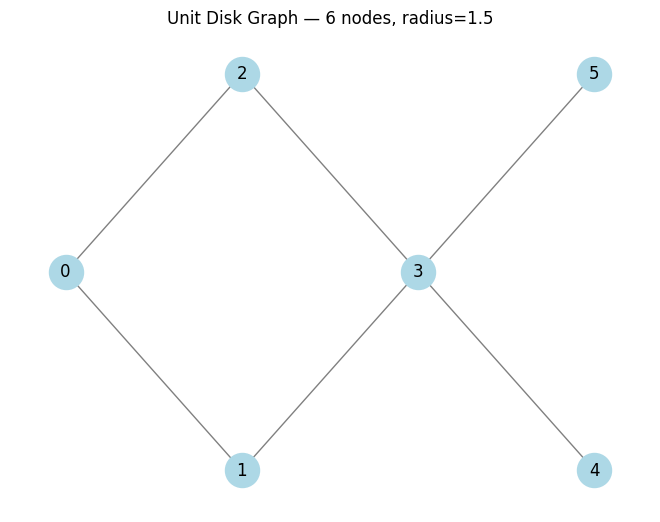

In [10]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Node positions in 2D space
pos = {
    0: (0.0, 1.0),
    1: (1.0, 0.0),
    2: (1.0, 2.0),
    3: (2.0, 1.0),
    4: (3.0, 0.0),
    5: (3.0, 2.0),
}

# Build Unit Disk Graph: connect nodes within distance threshold
radius = 1.5
G = nx.Graph()
G.add_nodes_from(pos.keys())
for i in pos:
    for j in pos:
        if i < j:
            dist = np.linalg.norm(np.array(pos[i]) - np.array(pos[j]))
            if dist <= radius:
                G.add_edge(i, j)

print(f"Nodes : {list(G.nodes())}")
print(f"Edges : {list(G.edges())}")

nx.draw(G, pos=pos, with_labels=True, node_color="lightblue",
        node_size=600, font_size=12, edge_color="gray")
plt.title(f"Unit Disk Graph — 6 nodes, radius={radius}")
plt.show()

### Step 2: Solve with the quantum approach

Rather than going through `Solver`/`SolverConfig`, we call each pipeline step directly: embed the QUBO onto a register, build a drive schedule, compile a program, and run it on a backend. The steps below reproduce `SolverConfig()`'s defaults — BLaDE embedding, a local-energy-scale drive, and a local emulator — so the result can be compared directly with the object-API version.

In [ ]:
import qoolqit

from qubosolver import (
    matrix,
    Instance,
    LocalEmulator,
    Solution,
    embedding,
    drive_shaping,
    solving,
)

# define QUBO
Q = matrix.tensor([
    [-4.0, 1.0, 2.0, 1.5, 2.3, 0.9, 1.8, 2.7, 1.2],
    [ 1.0,-3.2, 1.7, 2.1, 0.8, 1.9, 2.2, 1.1, 1.6],
    [ 2.0, 1.7,-5.1, 0.7, 2.5, 1.3, 2.6, 1.4, 2.0],
    [ 1.5, 2.1, 0.7,-2.7, 1.2, 2.4, 0.6, 1.8, 2.1],
    [ 2.3, 0.8, 2.5, 1.2,-6.3, 1.0, 1.7, 2.8, 1.5],
    [ 0.9, 1.9, 1.3, 2.4, 1.0,-4.5, 2.3, 1.6, 0.9],
    [ 1.8, 2.2, 2.6, 0.6, 1.7, 2.3,-3.8, 1.2, 2.2],
    [ 2.7, 1.1, 1.4, 1.8, 2.8, 1.6, 1.2,-5.9, 1.4],
    [ 1.2, 1.6, 2.0, 2.1, 1.5, 0.9, 2.2, 1.4,-2.4],
])
instance = Instance(Q)

# Default device and backend used by `SolverConfig()`.
device = qoolqit.AnalogDeviceWithDMM()
backend = LocalEmulator()

# Embed the QUBO onto a register (default embedding: BLaDE).
register = embedding.blade.embed_for_device(instance, device)

# Build a drive schedule for that register (default drive shaping: local-energy-scale).
drive = drive_shaping.local_energy_scale.build_drive(instance, register, device=device)

# Compile and run the program.
program = solving.analog_quantum_sampling.compile(register, drive, device)
job = backend.run(program)

# Interpret the results as a Solution.
quantum_solution = Solution.from_results(job.results(), instance)

In [15]:
quantum_solution

Solution(bitstrings=tensor([[0, 0, 1, 0, 0, 1, 0, 1, 0],
        [0, 0, 1, 1, 0, 0, 0, 1, 0],
        [0, 1, 1, 0, 0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 1, 0, 1, 1],
        [0, 1, 1, 0, 0, 1, 0, 1, 0],
        [0, 0, 1, 0, 0, 1, 0, 1, 1],
        [0, 0, 0, 0, 1, 1, 0, 1, 1],
        [0, 0, 1, 1, 0, 1, 0, 1, 0]], dtype=torch.int8), costs=tensor([-6.9000, -5.9000, -5.8000, -5.0000, -0.7000, -0.7000, -0.7000,  0.2000]), counts=tensor([824,  19,  22,   2, 121,   3,   5,   4]), probabilities=tensor([0.8240, 0.0190, 0.0220, 0.0020, 0.1210, 0.0030, 0.0050, 0.0040]))

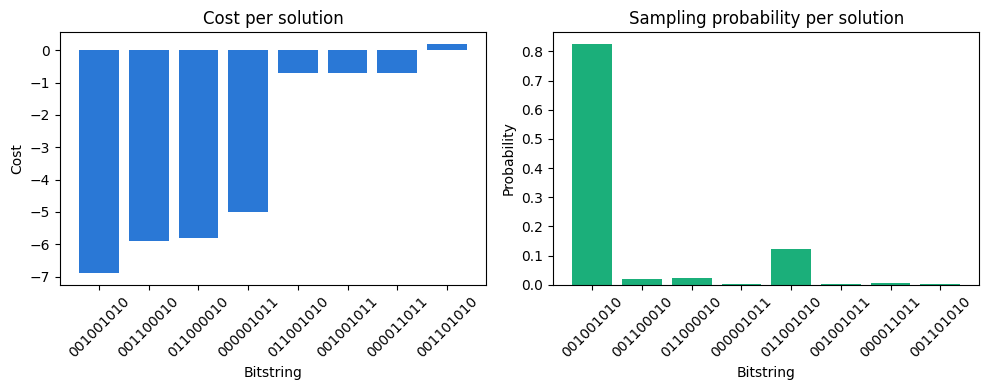

In [16]:
import matplotlib.pyplot as plt

bitstrings = ["".join(map(str, row.tolist())) for row in quantum_solution.bitstrings]
costs = quantum_solution.costs.tolist()
probabilities = quantum_solution.probabilities.tolist()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(bitstrings, costs, color="#2a78d6")
axes[0].set_title("Cost per solution")
axes[0].set_xlabel("Bitstring")
axes[0].set_ylabel("Cost")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(bitstrings, probabilities, color="#1baf7a")
axes[1].set_title("Sampling probability per solution")
axes[1].set_xlabel("Bitstring")
axes[1].set_ylabel("Probability")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

### Step 3: Solve with the classical approach

For the classical approach, we call the solving algorithm — here, tabu search — directly on a starting bitstring, instead of going through `ClassicalSolvingConfig`. This reproduces what `Solver` does internally for `ClassicalSolvingConfig(algorithm="tabu_search", time_limit=10.0)`: a single random starting bitstring and up to 100 iterations.

In [17]:
from qubosolver import Instance, bitstrings, matrix, solving, torch_rng

# define QUBO
Q = matrix.tensor([
    [-4.0, 1.0, 2.0, 1.5, 2.3, 0.9, 1.8, 2.7, 1.2],
    [ 1.0,-3.2, 1.7, 2.1, 0.8, 1.9, 2.2, 1.1, 1.6],
    [ 2.0, 1.7,-5.1, 0.7, 2.5, 1.3, 2.6, 1.4, 2.0],
    [ 1.5, 2.1, 0.7,-2.7, 1.2, 2.4, 0.6, 1.8, 2.1],
    [ 2.3, 0.8, 2.5, 1.2,-6.3, 1.0, 1.7, 2.8, 1.5],
    [ 0.9, 1.9, 1.3, 2.4, 1.0,-4.5, 2.3, 1.6, 0.9],
    [ 1.8, 2.2, 2.6, 0.6, 1.7, 2.3,-3.8, 1.2, 2.2],
    [ 2.7, 1.1, 1.4, 1.8, 2.8, 1.6, 1.2,-5.9, 1.4],
    [ 1.2, 1.6, 2.0, 2.1, 1.5, 0.9, 2.2, 1.4,-2.4],
])
instance = Instance(Q)

# A single random starting bitstring, as `Solver` does internally for tabu search.
starts = bitstrings.rand(1, instance.size, rng=torch_rng("global"))

# Run tabu search directly on that starting bitstring.
classical_solution = solving.tabu_search.solve(instance, starts=starts, max_iter=100, time_limit=10.0)

In [18]:
classical_solution

Solution(bitstrings=tensor([[0, 0, 0, 0, 1, 1, 0, 0, 0]], dtype=torch.int8), costs=tensor([-8.8000]), counts=tensor([1]), probabilities=tensor([1.]))

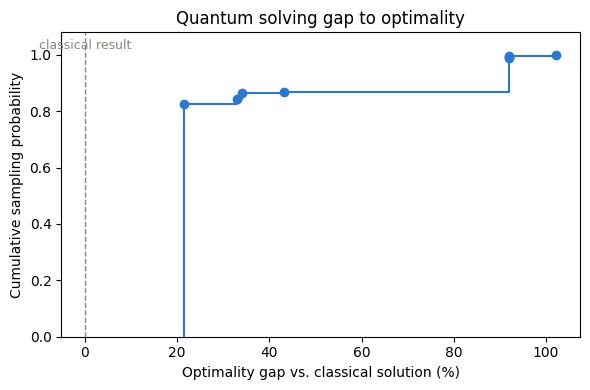

In [19]:
import matplotlib.pyplot as plt

optimal_cost = classical_solution.costs.min().item()

gaps_percent = 100.0 * (quantum_solution.costs - optimal_cost) / abs(optimal_cost)
probabilities = quantum_solution.probabilities

order = gaps_percent.argsort()
sorted_gaps = gaps_percent[order].tolist()
cumulative_probabilities = probabilities[order].cumsum(dim=0).tolist()

fig, ax = plt.subplots(figsize=(6, 4))
ax.step(
    [sorted_gaps[0]] + sorted_gaps,
    [0.0] + cumulative_probabilities,
    where="post",
    color="#2a78d6",
)
ax.scatter(sorted_gaps, cumulative_probabilities, color="#2a78d6", zorder=3)
ax.axvline(0.0, color="#898781", linestyle="--", linewidth=1)
ax.text(0.0, 1.02, "classical result", color="#898781", ha="center", fontsize=9)

ax.set_title("Quantum solving gap to optimality")
ax.set_xlabel("Optimality gap vs. classical solution (%)")
ax.set_ylabel("Cumulative sampling probability")
ax.set_ylim(0, 1.08)
fig.tight_layout()
plt.show()

The functional API mirrors each step the `Solver` performs internally — embedding, drive shaping, compiling, running, and interpreting results — as a separate call you can inspect, swap out, or run independently. See [QUBO Solver in full](02-qubosolver-in-full.ipynb) and the other tutorials for a closer look at each of these steps.